# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
import os

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)
from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

ML runs from high and low noise

In [2]:
runs_to_download = []
# Sparsity time points
runs_to_download.extend(
    mlflow.search_runs(filter_string=f"attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction'",
                        experiment_ids=['9'], output_format='list'))
# All time points (from original run)
runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-06-29 08:59:58,765 - INFO - Downloading artifacts for run cbf58daecb7d4c518b57bce6f1459b4f


18


2026-06-29 09:00:27,695 - INFO - Downloading artifacts for run 239cb48709fa407db9da20b91e19b20a
2026-06-29 09:00:30,078 - INFO - Downloading artifacts for run 29e427d256d947a191f8c9f92af4af46
2026-06-29 09:00:32,189 - INFO - Downloading artifacts for run 7ee463add0df4464ae52cb24e999a0ba
2026-06-29 09:00:34,115 - INFO - Downloading artifacts for run 7fc222d9b55a401ba35f2047069b5434
2026-06-29 09:00:36,045 - INFO - Downloading artifacts for run f9ec902f7d804ac29cda2a3455524962
2026-06-29 09:00:37,763 - INFO - Downloading artifacts for run b8eb6120f7eb4c59b43f977189b2d948
2026-06-29 09:00:39,476 - INFO - Downloading artifacts for run e16cf457a1534cc8888b6cf9c84d84cf
2026-06-29 09:00:41,143 - INFO - Downloading artifacts for run f2ff6717b2064da4b14ae541cb9a2bbb
2026-06-29 09:00:42,833 - INFO - Downloading artifacts for run e80872f95d31418782eb600ead86eba6
2026-06-29 09:00:44,504 - INFO - Downloading artifacts for run aa8c89cba5f14125b64a3ffd771f0bee
2026-06-29 09:00:46,353 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.800421,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.825941,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.049305,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b


In [3]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None),
        'nr_timepoints': run.data.params.get('n_timepoints_training', 21)
        })
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes,nr_timepoints
0,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11
1,239cb48709fa407db9da20b91e19b20a,MLP,None,11
2,29e427d256d947a191f8c9f92af4af46,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",11
3,7ee463add0df4464ae52cb24e999a0ba,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",11
4,7fc222d9b55a401ba35f2047069b5434,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",11
5,f9ec902f7d804ac29cda2a3455524962,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",11
6,b8eb6120f7eb4c59b43f977189b2d948,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",6
7,e16cf457a1534cc8888b6cf9c84d84cf,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",6
8,f2ff6717b2064da4b14ae541cb9a2bbb,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",6
9,e80872f95d31418782eb600ead86eba6,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",6


In [4]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add noiseless expression values

In [5]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-06-29 09:01:08,618 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,656 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,678 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,693 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,720 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,764 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,783 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-29 09:01:08,819 - WARNING - Connection p

In [6]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,nr_timepoints
0,Node_0,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11
1,Node_1,0.0,0.800421,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11
2,Node_2,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11
3,Node_3,0.0,0.825941,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11
4,Node_4,0.0,0.049305,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11


In [7]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b


Merging

In [8]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

In [9]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,nr_timepoints,ground_truth_from_simulation,run_id_from_simulation
0,Node_0,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11,0.022225,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.800421,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11,0.557310,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11,0.080057,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.825941,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11,0.702816,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.049305,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",11,0.057769,f02bf732b2ba4817b254bd5174f1549b
...,...,...,...,...,...,...,...,...,...,...,...,...
1514995,Node_45,1.0,1.003480,0.821199,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.925542,f02bf732b2ba4817b254bd5174f1549b
1514996,Node_46,1.0,0.394155,0.294828,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.321352,f02bf732b2ba4817b254bd5174f1549b
1514997,Node_47,1.0,0.190476,0.136453,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.138196,f02bf732b2ba4817b254bd5174f1549b
1514998,Node_48,1.0,0.806056,0.756552,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.833160,f02bf732b2ba4817b254bd5174f1549b


<Axes: xlabel='ground_truth_from_simulation', ylabel='ground_truth_from_pred_df'>

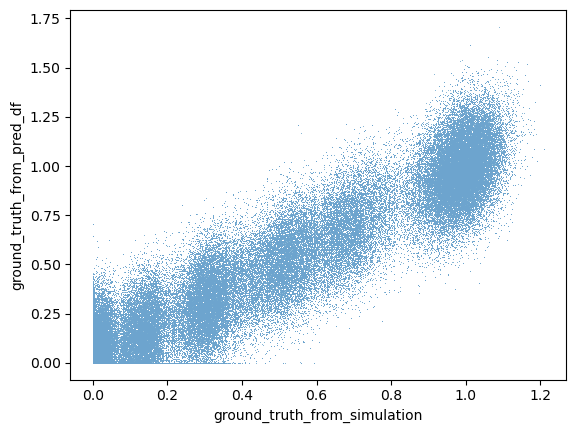

In [10]:
sns.scatterplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', s=2, alpha=.2, marker='.')

In [11]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_timepoints']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints
0,Node_0,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.022225,11
1,Node_1,0.0,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.557310,11
2,Node_2,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.080057,11
3,Node_3,0.0,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.702816,11
4,Node_4,0.0,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.057769,11
...,...,...,...,...,...,...,...,...,...
1514995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,21
1514996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,21
1514997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,21
1514998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,21


In [12]:
import string
genes_to_letter_map = {}
i = 0
for genes in outcome['modelled_genes'].unique():
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
    i += 1
genes_to_letter_map

{"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'A',
 "['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'B',
 "['Node_9', 'Node_18', 'Node_14', 'Node_21', 'Node_36', 'Node_40', 'Node_41']": 'C',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'D',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'E'}

In [13]:
outcome['model_name_long'] = outcome['model_name'] + ' ' + outcome['modelled_genes'].map(genes_to_letter_map).fillna('')
outcome['model_name_long'].nunique()

6

In [14]:
outcome['model_name_long'].unique().tolist()

['HybridModel A',
 'MLP ',
 'HybridModel B',
 'HybridModel C',
 'HybridModel D',
 'HybridModel E']

In [15]:
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints,model_name_long
0,Node_0,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.022225,11,HybridModel A
1,Node_1,0.0,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.557310,11,HybridModel A
2,Node_2,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.080057,11,HybridModel A
3,Node_3,0.0,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.702816,11,HybridModel A
4,Node_4,0.0,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.057769,11,HybridModel A
...,...,...,...,...,...,...,...,...,...,...
1514995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,21,MLP
1514996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,21,MLP
1514997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,21,MLP
1514998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,21,MLP


In [16]:
outcome['time_point_phase'] = pd.cut(
    outcome['time'],
    bins=[0, 0.25, 0.5, 0.75, 1.0],
    labels=['early', 'mid-early', 'mid-late', 'late'],
    include_lowest=True
)
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints,model_name_long,time_point_phase
0,Node_0,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.022225,11,HybridModel A,early
1,Node_1,0.0,0.800421,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.557310,11,HybridModel A,early
2,Node_2,0.0,0.000000,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.080057,11,HybridModel A,early
3,Node_3,0.0,0.825941,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.702816,11,HybridModel A,early
4,Node_4,0.0,0.049305,KO: Node_47. Env: None,cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.057769,11,HybridModel A,early
...,...,...,...,...,...,...,...,...,...,...,...
1514995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,21,MLP,late
1514996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,21,MLP,late
1514997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,21,MLP,late
1514998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,21,MLP,late


In [17]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [18]:
from copy import deepcopy
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [19]:
double_ko_df

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints,model_name_long,time_point_phase
20900,Node_0,0.0,0.148432,"KO: Node_8, Node_15. Env: None",cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.102054,11,HybridModel A,early
20901,Node_1,0.0,0.602155,"KO: Node_8, Node_15. Env: None",cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.520959,11,HybridModel A,early
20902,Node_2,0.0,0.653237,"KO: Node_8, Node_15. Env: None",cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.628458,11,HybridModel A,early
20903,Node_3,0.0,0.483115,"KO: Node_8, Node_15. Env: None",cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.398028,11,HybridModel A,early
20904,Node_4,0.0,0.287592,"KO: Node_8, Node_15. Env: None",cbf58daecb7d4c518b57bce6f1459b4f,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.271006,11,HybridModel A,early
...,...,...,...,...,...,...,...,...,...,...,...
1502395,Node_45,1.0,0.985998,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,1.096496,21,MLP,late
1502396,Node_46,1.0,0.353063,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.310380,21,MLP,late
1502397,Node_47,1.0,0.186373,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.119164,21,MLP,late
1502398,Node_48,1.0,0.807091,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.939778,21,MLP,late


In [39]:
from sklearn.metrics import mean_squared_error
import re

groupby_list = [
    'model_name', 
    'time',
    # 'modelled_genes',
    # 'time_point_phase',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_timepoints'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

mse_df_long_model_name['nr_timepoints'] = mse_df_long_model_name['nr_timepoints'].astype(int)
import matplotlib.colors as mcolors

# hybrid_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' in n]
# mlp_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' not in n]

# hybrid_colours = sns.blend_palette(["#f5a623", "#d45f00"], n_colors=len(hybrid_names))
# mlp_colours = sns.blend_palette(["#4a90d9", "#003f7f"], n_colors=len(mlp_names))

# palette = {name: colour for name, colour in zip(hybrid_names, hybrid_colours)}
# palette.update({name: colour for name, colour in zip(mlp_names, mlp_colours)})
# palette = {name: mcolors.to_hex(colour) for name, colour in palette.items()}

# mse_df_long_model_name


In [32]:
mse_df_long_model_name.nr_timepoints.value_counts()

nr_timepoints
21    60000
11    60000
6     60000
Name: count, dtype: int64

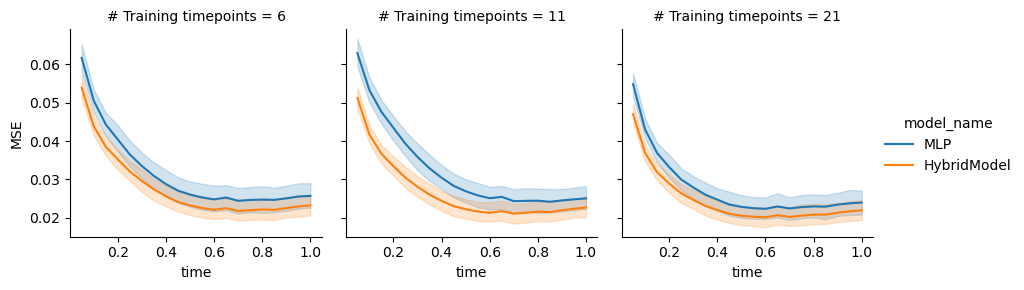

In [45]:
ignore_0 = mse_df_long_model_name[mse_df_long_model_name['time'] > 0]
ignore_0 = ignore_0.rename(columns={'nr_timepoints': '# Training timepoints'})
g = sns.relplot(data=ignore_0, 
            x='time', y=DfColumnNames.MSE_COL,
             col='# Training timepoints', hue='model_name', height=3, aspect=1, 
             kind='line', hue_order=['MLP', 'HybridModel'], estimator='mean')
# g.set(yscale='log')

g.savefig("mse_over_time_sparser_timepoints_hybrids_together.pdf", dpi=600, bbox_inches='tight')

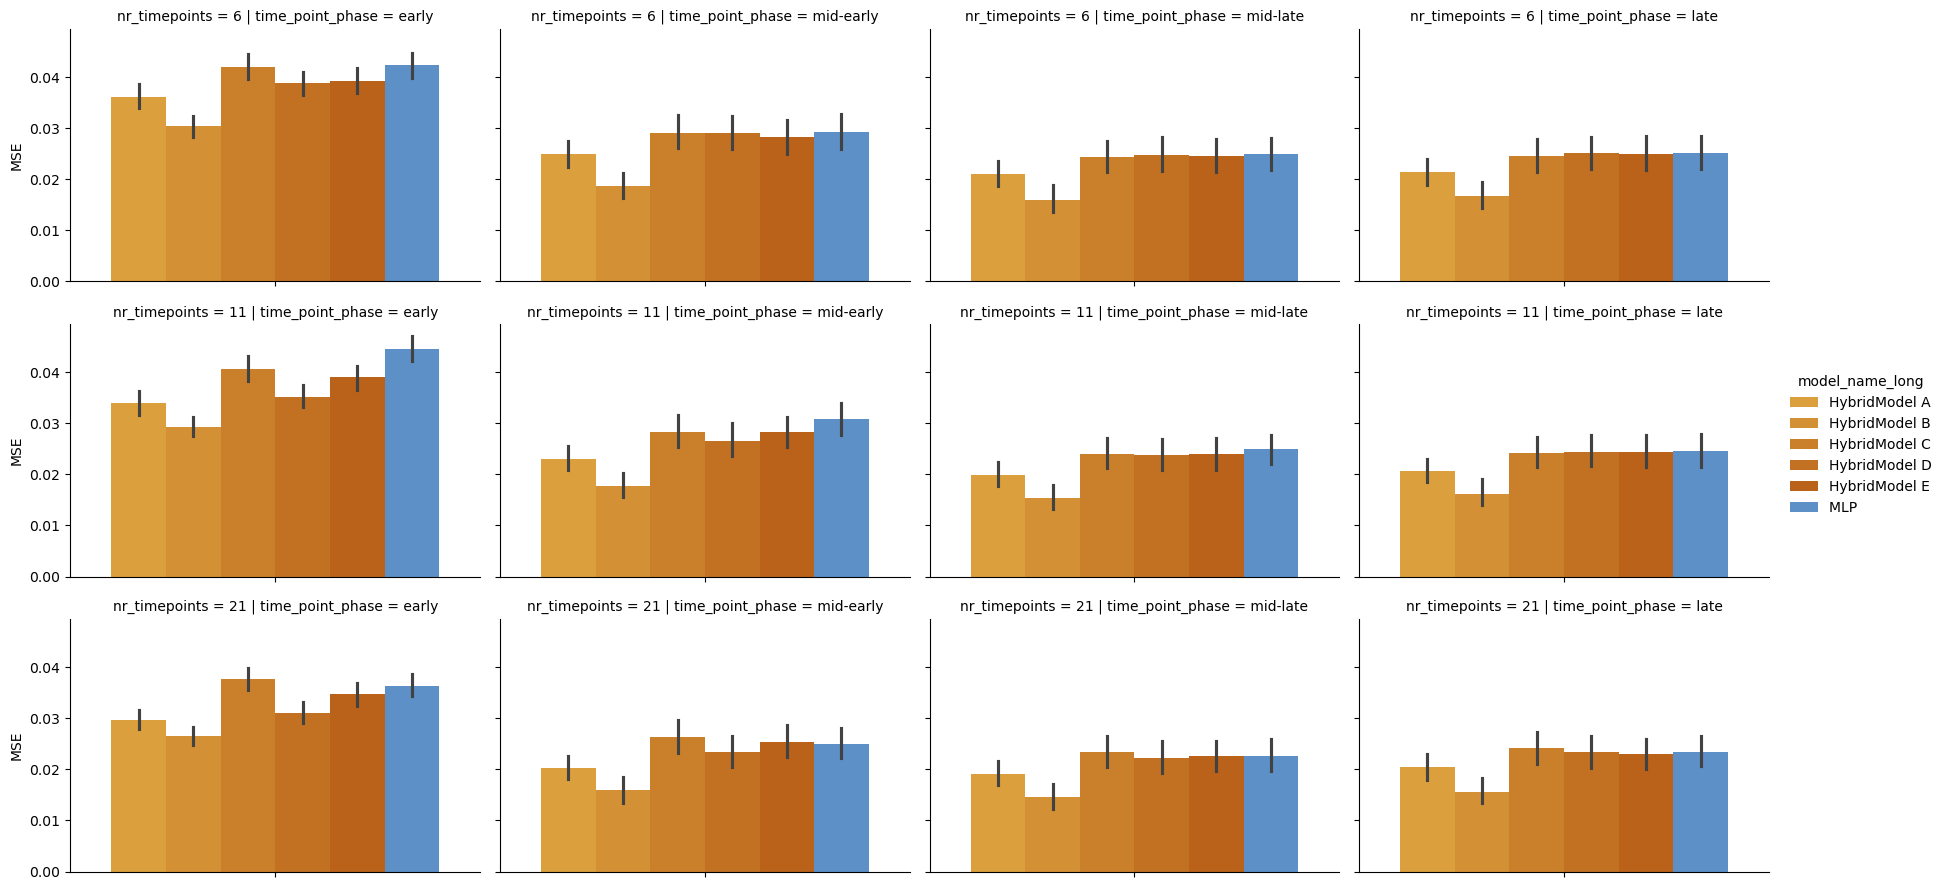

In [21]:
sns.catplot(data=mse_df_long_model_name, row='nr_timepoints', row_order=[6, 11, 21], col='time_point_phase', 
            y='MSE', hue='model_name_long', height=3, aspect=1.5, kind='bar', palette=palette)

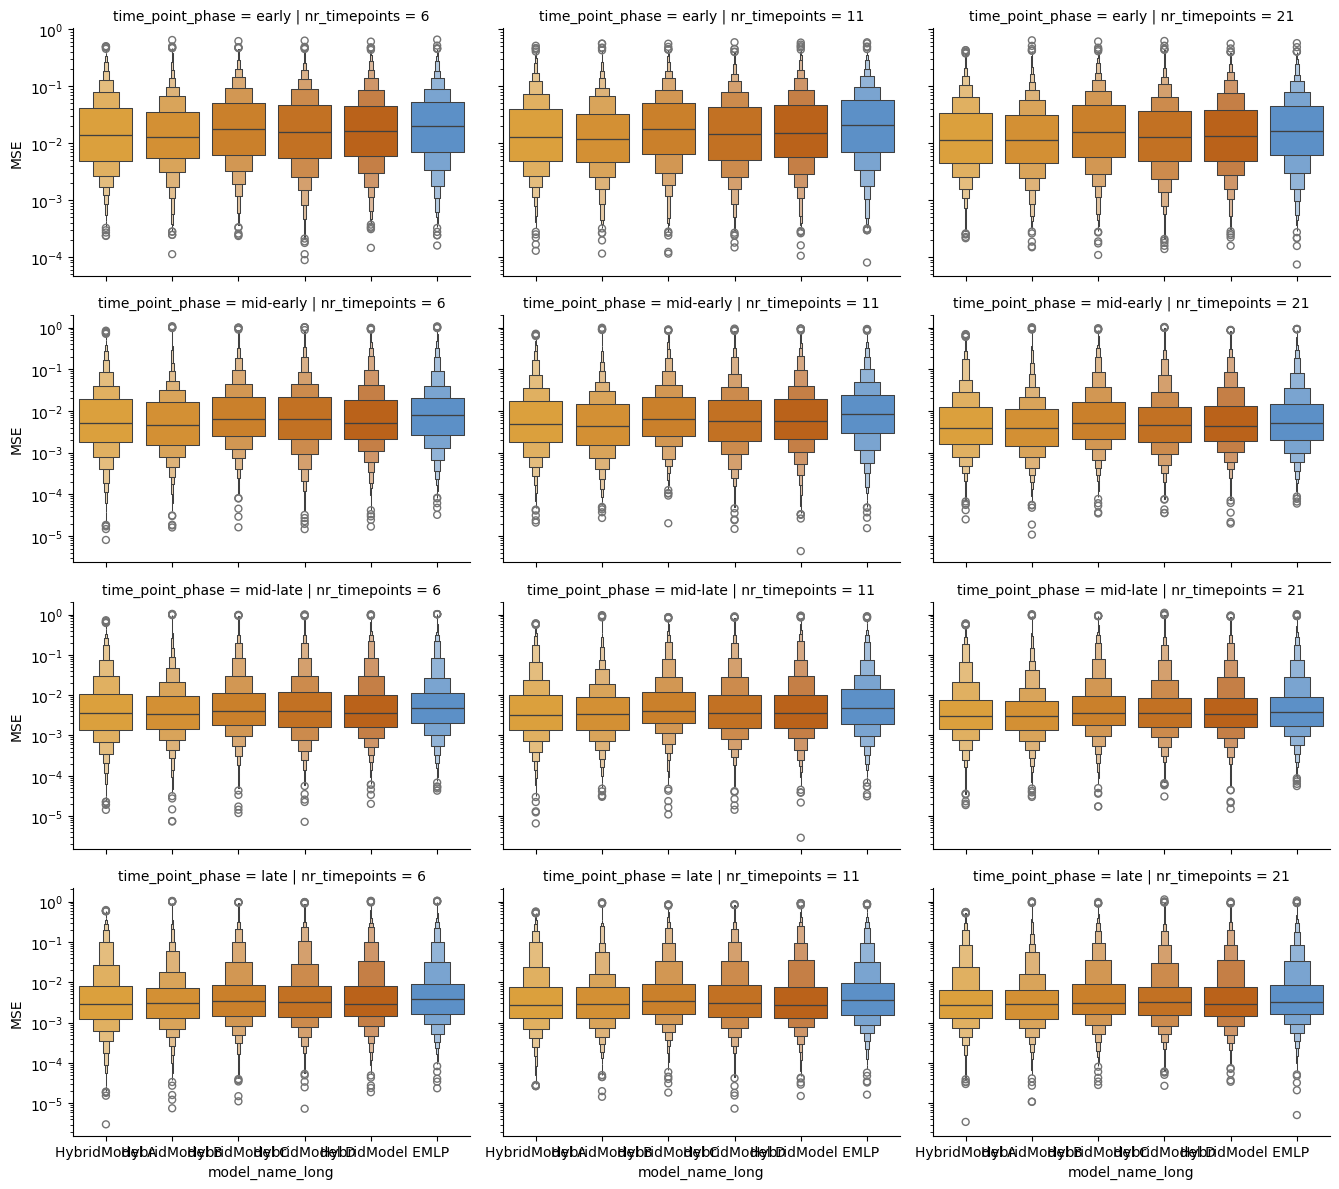

In [22]:
sns.catplot(data=mse_df_long_model_name, col='nr_timepoints', col_order=[6, 11, 21], row='time_point_phase', 
            y='MSE', x='model_name_long', hue='model_name_long', height=3, aspect=1.5, kind='boxen', log_scale=True,
           sharey='row', palette=palette)

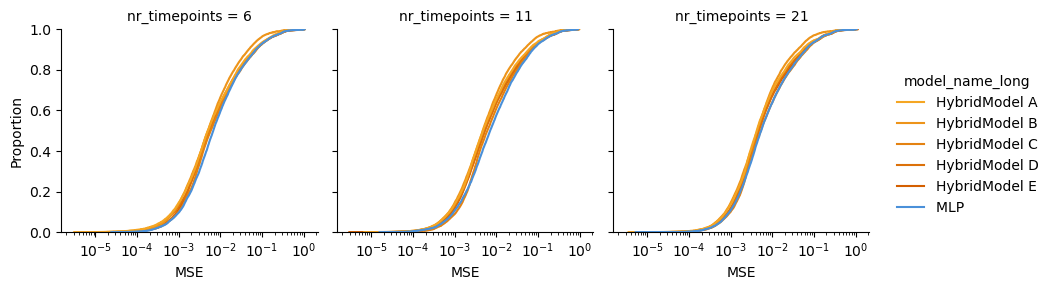

In [23]:
g = sns.displot(data=mse_df_long_model_name, col='nr_timepoints', col_order=[6, 11, 21], x='MSE', hue='model_name_long', palette=palette, kind='ecdf', log_scale=(True), height=3)

for ax in g.axes.flat:
    lines = ax.get_lines()
    for line in lines:
        if mcolors.to_hex(line.get_color()) in [palette[name] for name in mlp_names]:
            line.set_zorder(10)
# g.savefig("noise_level_ecdf.pdf", dpi=600, bbox_inches='tight', )

In [24]:
from sklearn.metrics import mean_squared_error
import re

groupby_list = [
    'model_name_long', 
    'modelled_genes',
    'time',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_timepoints'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

mse_df_long_model_name['nr_timepoints'] = mse_df_long_model_name['nr_timepoints'].astype(int)
import matplotlib.colors as mcolors

hybrid_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' in n]
mlp_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' not in n]

hybrid_colours = sns.blend_palette(["#f5a623", "#d45f00"], n_colors=len(hybrid_names))
mlp_colours = sns.blend_palette(["#4a90d9", "#003f7f"], n_colors=len(mlp_names))

palette = {name: colour for name, colour in zip(hybrid_names, hybrid_colours)}
palette.update({name: colour for name, colour in zip(mlp_names, mlp_colours)})
palette = {name: mcolors.to_hex(colour) for name, colour in palette.items()}

mse_df_long_model_name


,model_name_long,modelled_genes,time,gene,condition,nr_timepoints,MSE
0,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.0,Node_0,"KO: Node_0, Node_13. Env: None",21,0.010221
1,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.0,Node_0,"KO: Node_0, Node_13. Env: None",11,0.010221
2,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.0,Node_0,"KO: Node_0, Node_13. Env: None",6,0.010221
3,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.0,Node_0,"KO: Node_0, Node_19. Env: None",21,0.004608
4,HybridModel A,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",0.0,Node_0,"KO: Node_0, Node_19. Env: None",11,0.004608
...,...,...,...,...,...,...,...
944995,MLP,NaN,1.0,Node_9,"KO: Node_8, Node_16. Env: None",11,0.000353
944996,MLP,NaN,1.0,Node_9,"KO: Node_8, Node_16. Env: None",6,0.000482
944997,MLP,NaN,1.0,Node_9,"KO: Node_8, Node_31. Env: None",21,0.001203
944998,MLP,NaN,1.0,Node_9,"KO: Node_8, Node_31. Env: None",11,0.001286


In [25]:
ignore_0 = mse_df_long_model_name[mse_df_long_model_name['time'] > 0]
ignore_0 = ignore_0.rename(columns={'nr_timepoints': '# Training timepoints'})

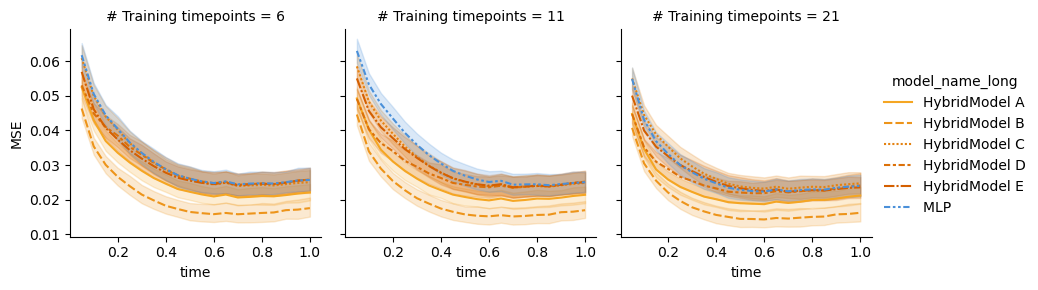

In [26]:
g = sns.relplot(data=ignore_0, 
            x='time', y=DfColumnNames.MSE_COL,
             col='# Training timepoints', hue='model_name_long', style='model_name_long', palette=palette, height=3, aspect=1, 
             kind='line')
# g.set(yscale='log')

# g.savefig("mse_over_time_sparser_timepoints.pdf", dpi=600, bbox_inches='tight')

Cells below only work when groupby was called with `model_name`

In [27]:
mlp_mse = mse_df_long_model_name[mse_df_long_model_name['model_name'] == 'MLP'][['gene', 'condition', 'nr_timepoints', 'MSE', 'time_point_phase']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df_long_model_name[mse_df_long_model_name['model_name'] == 'HybridModel'][['gene', 'condition', 'nr_timepoints', 'MSE', 'modelled_genes', 'time_point_phase']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_timepoints', 'time_point_phase'])
paired = annotate_kos_in_df(paired)

KeyError: 'model_name'

In [ ]:
paired = paired[paired['gene_in_mm'] == False]

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_timepoints',  row='time_point_phase', hue='ko_in_mm',
                  alpha=.75, s=5, col_order=natsorted(paired['nr_timepoints'].unique()), height=3, aspect=1,
                )
# g.figure.set_size_inches(9, 3) 

g.set(xscale='log', yscale='log')

# from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# # ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
# ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, zorder=0)
#     ax.set_xticks(ticks)
#     ax.set_yticks(ticks)
#     ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
#     ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
#     ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
#     for collection in ax.collections:
#         collection.set_rasterized(True)


# for handle in g.legend.legend_handles:
#     try:
#         handle.set_markersize(5)
#     except AttributeError:
#         pass

# for text in g._margin_titles_texts:
#     text.set_visible(False)